# **Hito 1 · Preprocesado de documentos y consultas con spaCy**

---
**Proyecto PLN (UC3M, 2026/27)** — Chatbot RAG sobre documentación de misiones espaciales.

**Issue:** *Preprocesar documentos y consultas con spaCy*

* Aplicar **lematización**, **filtrado por categoría gramatical**, **eliminación de stopwords** y **filtrado por frecuencia documental**.
* Aplicar a las **consultas** exactamente el **mismo preprocesado** que a los documentos.

---

**Entrada:** `fragmentos_base/misiones_300.jsonl` (fragmentos de 300 palabras generados por `scripts/segmentar_corpus.py`). La unidad de indexación es el **fragmento**, así que todas las estadísticas (frecuencia documental, etc.) se calculan sobre fragmentos, tal y como indica el enunciado del Hito 1.

**Salida** (carpeta `preprocesado/`), que reutilizarán los baselines TF-IDF y BM25:

| Fichero | Contenido |
|---|---|
| `lemas_spacy.jsonl` | Lemas de cada fragmento tras spaCy (antes de n-gramas y filtro por frecuencia). Permite probar otros parámetros sin volver a ejecutar spaCy |
| `fragmentos_preprocesados.jsonl` | `chunk_id`, `doc_id` y `tokens` finales de cada fragmento |
| `diccionario.dict` | Diccionario de Gensim ya filtrado por frecuencia documental |
| `ngramas.phrases` | Modelo de n-gramas (Gensim `Phrases`, congelado) |
| `config_preprocesado.json` | Parámetros usados (para reproducibilidad) |
| `consultas_preprocesadas.jsonl` | Solo si existe `queries.jsonl` en la raíz del repositorio |

**Base:** el pipeline sigue el notebook *Text Vectorization I* (secciones 1.2, 1.3, 2.2, 2.3 y 4.1) y el *spaCy tutorial*. Las adaptaciones al corpus están marcadas con 🆕.

## **0. Configuración**

In [1]:
# Colab-specific helpers (they are skipped when running the notebook elsewhere)
import sys
IN_COLAB = 'google.colab' in sys.modules
if IN_COLAB:
    # Fancy (interactive) display of dataframes
    get_ipython().run_line_magic('load_ext', 'google.colab.data_table')

# To wrap long text lines in outputs
from IPython.display import HTML, display
def set_css(*args, **kwargs):
    display(HTML('<style> pre { white-space: pre-wrap; } </style>'))
get_ipython().events.register('pre_run_cell', set_css)

In [2]:
# Packages that are not preinstalled in Google Colab (en local: pip install -r requirements.txt)
%pip install --quiet gensim wordninja

import spacy
try:
    spacy.load('en_core_web_sm')
except OSError:
    !{sys.executable} -m spacy download en_core_web_sm

Note: you may need to restart the kernel to use updated packages.


In [3]:
import os
import json
import re
import time
from collections import Counter
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import spacy
import wordninja
from gensim.corpora import Dictionary
from gensim.models.phrases import Phrases, FrozenPhrases

%matplotlib inline
plt.rcParams['figure.figsize'] = [8, 4]
pd.set_option('display.max_colwidth', 120)

print('spaCy', spacy.__version__)

spaCy 3.8.18


### Ficheros de datos

El notebook está en la carpeta `notebooks/` del repositorio y lee los fragmentos de `fragmentos_base/misiones_300.jsonl`.

* **En local**, ejecutadlo desde `notebooks/`: `REPO_DIR = '..'` apunta a la raíz del repositorio.
* **En Google Colab**, copiad el repositorio a una carpeta de vuestro Google Drive (por ejemplo, con `!git clone` dentro de `/content/drive/My Drive/`) y actualizad `REPO_DIR` en consecuencia.

Los ficheros que genera este notebook se guardan en la carpeta `preprocesado/` del repositorio; los necesitaréis en el notebook de los baselines (TF-IDF y BM25).

In [4]:
REPO_DIR = '..'   # raíz del repositorio cuando el notebook se ejecuta en local desde notebooks/

if IN_COLAB:
    from google.colab import drive
    drive.mount('/content/drive')
    REPO_DIR = '/content/drive/My Drive/uc3m-pln-rag-2026'  # UPDATE THIS ACCORDING TO WHERE YOU STORED THE REPOSITORY!!!!

print(os.listdir(REPO_DIR))

REPO_DIR = Path(REPO_DIR)
FRAGMENTS_PATH = REPO_DIR / 'fragmentos_base' / 'misiones_300.jsonl'
QUERIES_PATH = REPO_DIR / 'queries.jsonl'          # lo generará el issue de consultas de evaluación
OUT_DIR = REPO_DIR / 'preprocesado'
OUT_DIR.mkdir(exist_ok=True)

LEMMAS_CACHE = OUT_DIR / 'lemas_spacy.jsonl'
FORCE_SPACY = False   # True para volver a ejecutar spaCy aunque exista la caché (~5 min en CPU)

['.git', '.gitignore', 'corpus', 'fragmentos_base', 'notebooks', 'README.md', 'scripts']


Todos los parámetros del preprocesado están juntos aquí, para que sea fácil documentarlos en `MILESTONE_1.md` y probar variantes. Cada uno se justifica más abajo, en la sección donde se usa.

In [5]:
CONFIG = {
    # spaCy
    'spacy_model': 'en_core_web_sm',
    'valid_pos': ['NOUN', 'VERB', 'ADJ', 'PROPN'],   # igual que en Text Vectorization I
    'min_token_len': 2,            # 🆕 descarta letras sueltas (restos de OCR, unidades 'm', 's'...)
    'keep_identifiers': True,      # 🆕 conserva números y códigos alfanuméricos (Apollo 11, STS-129, Astra 2B, 1969)
    'max_identifier_len': 4,
    'ocr_resegment': True,         # 🆕 re-segmenta con wordninja el texto OCR con letras separadas
    'specific_stopwords': [        # stopwords del dominio (en IMDB eran 'movie' y 'film')
        'et', 'al', 'fig', 'figure', 'table', 'page', 'ref', 'eq', 'etc',
    ],
    # N-gramas (Gensim Phrases), como en la sección 2.2 de Text Vectorization I
    'use_ngrams': True,
    'ngram_min_count': 5,
    'ngram_threshold': 20,
    # Filtro por frecuencia documental (Dictionary.filter_extremes), sección 2.3
    'no_below': 2,                 # nº mínimo de fragmentos en los que debe aparecer un término
    'no_above': 0.5,               # proporción máxima de fragmentos en los que puede aparecer
}

## **1. Carga de los fragmentos**

In [6]:
fragments_df = pd.read_json(FRAGMENTS_PATH, lines=True)

print(f'{len(fragments_df):,} fragmentos de {fragments_df.doc_id.nunique():,} documentos')
print(fragments_df.groupby('source').agg(fragmentos=('chunk_id', 'size'), documentos=('doc_id', 'nunique')))
assert fragments_df.chunk_id.is_unique
fragments_df[['chunk_id', 'doc_id', 'title', 'source', 'word_count', 'text']].head()

14,522 fragmentos de 2,397 documentos
                     fragmentos  documentos
source                                     
Apollo press kits          1934           9
JPL PDFs                   2617          63
NTRS pilot                 3282          85
Wikipedia 1957–1999        3653        1085
Wikipedia 2000–2025        3036        1155


,chunk_id,doc_id,title,source,word_count,text
0,doc_0002__0001,doc_0002,AMC-8,Wikipedia 2000–2025,300,AMC-8\n\nNames | GE-8 (2000-2001) AMC-8 (2001-present) Aurora-3 (2000-present) Aurora-III\n\nMission type | Communic...
1,doc_0003__0001,doc_0003,Astra 2B,Wikipedia 2000–2025,300,Astra 2B\n\nMission type | Communications\n\nOperator | SES\n\nCOSPAR ID | 2000-054A\n\nSATCAT no. | 26494\n\nWebsit...
2,doc_0005__0001,doc_0005,CHAMP (satellite),Wikipedia 2000–2025,300,Challenging Minisatellite Payload\n\nArtist's impression of CHAMP\n\nMission type | Technology\n\nOperator | DLR\n\n...
3,doc_0006__0001,doc_0006,EchoStar VI,Wikipedia 2000–2025,300,EchoStar VI / BermudaSat 1\n\nMission type | Communication\n\nOperator | EchoStar / SES\n\nCOSPAR ID | 2000-038A\n\n...
4,doc_0007__0001,doc_0007,ASUSat-1,Wikipedia 2000–2025,300,ASUSat\n\nMission type | Communications\n\nOperator | ASU\n\nCOSPAR ID | 2000-004E\n\nSATCAT no. | 26065\n\nWebsite ...


## **2. Preprocesado paso a paso sobre un fragmento**

Como en la sección 1.2 de *Text Vectorization I*, aplicamos primero las cuatro etapas típicas a un único fragmento para ver qué hace cada una:

1. *Text wrangling* (limpieza del texto bruto)
2. Tokenización
3. Homogeneización (minúsculas, eliminar no alfanuméricos, lematización)
4. Limpieza (stopwords)

Elegimos un fragmento de los *Apollo press kits*, porque es donde está el problema de limpieza más importante del corpus.

In [7]:
example = fragments_df.loc[fragments_df.chunk_id == 'doc_3221__0020'].iloc[0]
print(example.chunk_id, '|', example.title, '|', example.source)
print(example.text[:700])

doc_3221__0020 | Apollo 7 Press Kit | Apollo press kits
r i e n t a t i o n i s known b u t i s determined t o be inaccurate, the f l i g h t plan c a l l s f o r one f u l l night pass f o r realignment of t h e IMU platform.

a w

C r e w work-rest cycles have been planned so t h a t a l l three crewmen are awake for a t l e a s t a half-hour before IMU o r i e n t a t i o n s that precede a maneuver using- t h e s e r v i c e propulsion system.

The f l i g h t plan schedules an hour f o r each meal period with a l l three crewmen e a t i n g together whenever possible. Other mission a c t i v i t i e s , such as experiments, s t a t u s r e p o r t s and maneuvers w i l l be k e p t t o a minimum during meal periods.

Spacecraft systems check


### *2.1. Text wrangling* 🆕 (adaptado al corpus)

En el notebook del profesor, `wrangle_text` hacía tres cosas: quitar etiquetas HTML con BeautifulSoup, quitar URLs con `re.sub` y expandir contracciones con `contractions.fix`. Las hemos revisado contra nuestros datos:

| Paso del notebook | ¿Lo aplicamos? | Motivo |
|---|---|---|
| Quitar HTML (BeautifulSoup) | **No** | El corpus ya es texto plano. Las ~530 coincidencias de `<...>` son basura de OCR que encierra texto real; BeautifulSoup lo borraría |
| Quitar URLs (`re.sub`) | **Sí** | El corpus ya viene sin URLs, pero es barato y las **consultas** sí podrían contenerlas |
| Expandir contracciones | **No** | spaCy ya separa `don't` → `do` + `n't`, y todas las formas expandidas (*is, are, will, not*...) son stopwords o verbos auxiliares que se eliminan después. No cambia el resultado y ahorra una dependencia |

Y añadimos dos limpiezas nuevas que necesita **nuestro** corpus (sobre todo los PDF históricos con OCR):

* **Letras separadas por espacios**: el OCR de los *Apollo press kits* produce cosas como `s t a i n l e s s steel` o `b u t i s determined` (aparece en ~1.800 de sus 1.934 fragmentos, y algunos están espaciados casi por completo). Si no hacemos nada, todas esas letras sueltas se pierden. Detectamos las secuencias de 3 o más letras sueltas, quitamos los espacios y volvemos a separar las palabras con [`wordninja`](https://github.com/keredson/wordninja), que segmenta texto sin espacios usando frecuencias de palabras del inglés: `b u t i s` → `butis` → `but is`. No es perfecto, pero los errores que deja suelen ser palabras raras que luego elimina el filtro por frecuencia documental.
* **Guiones de fin de línea**: `propul-\nsion` → `propulsion` (PDF).
* **Identificadores con guion o barra**: el tokenizador de spaCy en inglés **no separa** nombres como `STS-129`, `USA-180`, `Progress M-13` o `Soyuz MS-04`: los deja como un único token no alfabético, así que se perderían justo los nombres de las misiones. Separamos los guiones y barras entre letras/dígitos: `STS-129` → `STS 129` (después el detector de n-gramas puede volver a unirlos como `sts_129`).

In [8]:
URL_RE = re.compile(r'https?://\S+|www\.\S+')
HYPHEN_BREAK_RE = re.compile(r'(\w)-[ \t]*\n\s*(\w)')
SPACED_LETTERS_RE = re.compile(r'\b(?:[A-Za-z] ){2,}[A-Za-z]\b')   # 3 o más letras sueltas
ID_SEPARATOR_RE = re.compile(r'(?<=[A-Za-z0-9])[-/](?=[A-Za-z0-9])')
WHITESPACE_RE = re.compile(r'\s+')

def fix_spaced_letters(match):
    joined = match.group(0).replace(' ', '')
    return ' '.join(wordninja.split(joined)) if CONFIG['ocr_resegment'] else joined

def wrangle_text(text):
    text = URL_RE.sub(' ', text)
    text = HYPHEN_BREAK_RE.sub(r'\1\2', text)
    text = SPACED_LETTERS_RE.sub(fix_spaced_letters, text)
    text = ID_SEPARATOR_RE.sub(' ', text)
    return WHITESPACE_RE.sub(' ', text).strip()

wrangled_example = wrangle_text(example.text)
print(wrangled_example[:600])
print('\nIdentificadores:', wrangle_text('Soyuz MS-04 docked with the ISS; STS-129 and Progress M-13 (2000/2001)'))

rien tat ionis known but is determined t o be inaccurate, the flight plan calls for one full night pass for realignment of the IMU platform. a w Crew work rest cycles have been planned so that all three crewmen are awake for atleast a half hour before IMU orientations that precede a maneuver using- the service propulsion system. The flight plan schedules an hour for each meal period with all three crewmen eating together whenever possible. Other mission activities , such as experiments, status reports and maneuvers will be kept to a minimum during meal periods. Spacecraft systems checkouts wil

Identificadores: Soyuz MS 04 docked with the ISS; STS 129 and Progress M 13 (2000 2001)


### *2.2–2.4. Tokenización, homogeneización y limpieza con spaCy*

En *Text Vectorization I* se comparaban el stemmer de NLTK, el lematizador WordNet y el de spaCy, y la conclusión era usar **spaCy**, porque lematiza usando la categoría gramatical (POS) de cada palabra en su contexto (*is* → *be*, *does* → *do*). Así que hacemos las tres etapas con spaCy directamente:

* **Tokenización**: la hace el `tokenizer` de spaCy.
* **Homogeneización**: lemas (`token.lemma_`) en minúsculas. Nos quedamos con los tokens **alfabéticos** (`is_alpha`), lo que elimina signos de puntuación, `|` de las tablas de Wikipedia, etc.
* **Filtrado por categoría gramatical**: solo las palabras con contenido (`NOUN`, `VERB`, `ADJ`, `PROPN`), como en el notebook.
* **Limpieza**: quitamos las stopwords genéricas de spaCy (`nlp.Defaults.stop_words`) más las específicas del dominio.

Como en el notebook, cargamos `en_core_web_sm` desactivando `parser` y `ner`, que no hacen falta para lematizar y ralentizan mucho el proceso. El corpus está **en inglés**, así que usamos el modelo inglés.

🆕 Dos reglas adicionales, justificadas por el dominio:

* **Longitud mínima de 2**: elimina letras sueltas (restos de OCR, abreviaturas de unidades como `m`, `s`).
* **Números e identificadores**: el notebook solo conservaba tokens alfabéticos, pero en nuestro corpus muchos nombres de misión solo se distinguen por un número o un código (*Apollo 7* vs *Apollo 8*, *Voyager 1* vs *Voyager 2*, *STS-129*, *Astra 2B*). Conservamos, en minúsculas y sin lematizar, los tokens alfanuméricos de hasta 4 caracteres que contienen algún dígito (`11`, `129`, `2b`, `1969`), sea cual sea su POS (el tagger etiqueta estos códigos de forma muy irregular: `NUM`, `NOUN`, `X`...). Los que aparecen en un solo fragmento se eliminan después con el filtro por frecuencia. Se puede desactivar con `keep_identifiers=False` para compararlo en el baseline.

In [9]:
nlp = spacy.load(CONFIG['spacy_model'], disable=['parser', 'ner'])
print('Componentes activos:', nlp.pipe_names)

VALID_POS = set(CONFIG['valid_pos'])
STOPWORDS = set(nlp.Defaults.stop_words) | set(CONFIG['specific_stopwords'])

def normalize_token(tk):
    # Devuelve la forma normalizada del token, o None si hay que descartarlo
    text = tk.lower_
    if CONFIG['keep_identifiers'] and text.isalnum() and any(c.isdigit() for c in text):
        return text if len(text) <= CONFIG['max_identifier_len'] else None
    if not tk.is_alpha or tk.pos_ not in VALID_POS:
        return None
    lemma = tk.lemma_.lower()
    if len(lemma) < CONFIG['min_token_len'] or not lemma.isalpha():
        return None
    if lemma in STOPWORDS or tk.lower_ in STOPWORDS:
        return None
    return lemma

Componentes activos: ['tok2vec', 'tagger', 'attribute_ruler', 'lemmatizer']


Veamos qué le pasa a cada token del fragmento de ejemplo:

In [10]:
doc_example = nlp(wrangled_example)
pd.DataFrame(
    [(tk.text, tk.pos_, tk.lemma_.lower(), tk.is_stop, normalize_token(tk)) for tk in doc_example[:40]],
    columns=['token', 'POS', 'lema', 'stopword', 'resultado'],
)

,token,POS,lema,stopword,resultado
0,rien,PROPN,rien,False,rien
1,tat,NOUN,tat,False,tat
2,ionis,NOUN,ionis,False,ionis
3,known,VERB,know,False,know
4,but,CCONJ,but,True,NaN
5,is,AUX,be,True,NaN
6,determined,ADJ,determined,False,determined
7,t,NOUN,t,False,NaN
8,o,NOUN,o,False,NaN
9,be,AUX,be,True,NaN


In [11]:
example_tokens = [t for t in map(normalize_token, doc_example) if t]
print(f'{len(doc_example)} tokens de spaCy -> {len(example_tokens)} tokens tras el filtrado\n')
print(example_tokens)

154 tokens de spaCy -> 75 tokens tras el filtrado

['rien', 'tat', 'ionis', 'know', 'determined', 'inaccurate', 'flight', 'plan', 'night', 'pass', 'realignment', 'imu', 'platform', 'crew', 'work', 'rest', 'cycle', 'plan', 'crewman', 'awake', 'atleast', 'half', 'hour', 'imu', 'orientation', 'precede', 'maneuver', 'service', 'propulsion', 'system', 'flight', 'plan', 'schedule', 'hour', 'meal', 'period', 'crewman', 'eat', 'possible', 'mission', 'activity', 'experiment', 'status', 'report', 'maneuver', 'minimum', 'meal', 'period', 'spacecraft', 'system', 'checkout', 'schedule', 'periodi', 'crew', 'coincide', 'plan', 'check', 'list', 'procedure', 'lithium', 'hydroxide', 'canister', 'removal', 'carbon', 'dioxide', 'cabin', 'atmosphere', 'change', '12', 'hour', 'canister', 'remove', '10', 'hour', 'lift']


## **3. Preprocesado de todo el corpus**

Igual que en el ejercicio 5 de *Text Vectorization I* (`prepare_data`): aplicamos `wrangle_text`, procesamos los textos en lote con `nlp.pipe` (mucho más rápido que llamar a `nlp` texto a texto) y nos quedamos con los lemas válidos.

La misma función se usará **para las consultas**: esa es la garantía de que ambas se preprocesan igual.

Tarda unos 5 minutos en CPU para los ~14.500 fragmentos, así que guardamos el resultado en `lemas_spacy.jsonl` y, si ya existe, lo cargamos (poner `FORCE_SPACY = True` para recalcular).

In [12]:
def lemmatize_texts(texts, batch_size=128):
    # Texto bruto -> lista de lemas filtrados (wrangling + spaCy + POS + stopwords)
    cleaned = (wrangle_text(t) for t in texts)
    return [[t for t in map(normalize_token, doc) if t]
            for doc in nlp.pipe(cleaned, batch_size=batch_size)]

In [13]:
%%time
if LEMMAS_CACHE.exists() and not FORCE_SPACY:
    cache = pd.read_json(LEMMAS_CACHE, lines=True)
    assert cache.chunk_id.tolist() == fragments_df.chunk_id.tolist(), 'La caché no corresponde a estos fragmentos: usa FORCE_SPACY = True'
    lemmas = cache.lemmas.tolist()
    print('Lemas cargados de la caché')
else:
    lemmas = lemmatize_texts(fragments_df.text.tolist())
    with LEMMAS_CACHE.open('w', encoding='utf-8') as f:
        for chunk_id, toks in zip(fragments_df.chunk_id, lemmas):
            f.write(json.dumps({'chunk_id': chunk_id, 'lemmas': toks}, ensure_ascii=False) + '\n')
    print('Lemas calculados y guardados en', LEMMAS_CACHE.name)

print(' '.join(lemmas[0][:60]))

Lemas calculados y guardados en lemas_spacy.jsonl
amc 8 ge 8 2000 2001 amc 8 2001 present aurora 3 2000 present aurora iii mission type communications operator ge americom ses americom 2001 2009 ses world skies 2009 2011 ses 2011 present cospar id 2000 081b satcat website ses world skies amc 8 mission duration 15 year plan 25 year 10 month 22 day elapse spacecraft property spacecraft
CPU times: total: 3min 54s
Wall time: 3min 57s


## **4. Detección de n-gramas**

Como en la sección 2.2 de *Text Vectorization I*, usamos `Phrases` de Gensim para detectar términos que aparecen juntos con mucha frecuencia (`service_module`, `apollo_11`, `hubble_space_telescope`...). Al haber quitado ya stopwords, se puede usar directamente.

* `min_count = 5`: el notebook usaba 2 con 10.000 reseñas cortas; con ~14.500 fragmentos de 300 palabras subimos el mínimo para no crear bigramas a partir de coincidencias puntuales.
* `threshold = 20`: el mismo valor que en el notebook.

🆕 Congelamos el modelo (`freeze()`): ocupa mucho menos, es más rápido, y basta para transformar textos nuevos (las consultas), que es lo único que necesitamos de él después. Igual que dice el notebook, *el modelo de n-gramas es parte del preprocesado: cualquier texto nuevo (p. ej. una consulta) tiene que transformarse con el mismo modelo*.

⚠️ Al unir `apollo 11` en `apollo_11`, el fragmento deja de contener el unigrama `apollo`. Esto puede ayudar (términos más específicos) o perjudicar (una consulta que solo dice "Apollo" ya no encaja). Por eso es un parámetro (`use_ngrams`) que conviene comparar en el issue de los baselines.

In [14]:
%%time
if CONFIG['use_ngrams']:
    phrase_model = Phrases(lemmas, min_count=CONFIG['ngram_min_count'], threshold=CONFIG['ngram_threshold']).freeze()
    corpus = [phrase_model[doc] for doc in lemmas]
else:
    phrase_model = None
    corpus = lemmas

ngram_counts = Counter(t for doc in corpus for t in doc if '_' in t)
print(f'{len(phrase_model.phrasegrams) if phrase_model else 0:,} n-gramas detectados; los más frecuentes en el corpus:')
print(ngram_counts.most_common(40))

13,679 n-gramas detectados; los más frecuentes en el corpus:
[('spacecraft_property', 2099), ('orbital_parameter', 2038), ('reference_system', 1909), ('cospar_id', 1829), ('mission_duration', 1748), ('start_mission', 1632), ('solar_wind', 1603), ('space_shuttle', 1416), ('magnetic_field', 1355), ('mass_kg', 1212), ('landing_site', 1163), ('air_force', 1086), ('space_station', 1079), ('low_earth', 1074), ('united_states', 1052), ('km_mi', 986), ('geocentric_regime', 966), ('utc_rocket', 925), ('mi_inclination', 924), ('solar_array', 920), ('international_space', 907), ('mi_apogee', 903), ('carbon_dioxide', 890), ('deep_space', 833), ('lunar_surface', 816), ('geocentric_orbit', 814), ('second_stage', 803), ('mission_specialist', 768), ('high_resolution', 739), ('perigee_altitude', 730), ('mass_kilogram', 728), ('solar_panel', 681), ('period_minute', 623), ('flight_engineer', 611), ('kennedy_space', 599), ('mission_disposal', 565), ('ground_station', 558), ('lunar_module', 557), ('attitud

In [15]:
# Algunos n-gramas relacionados con nombres de misiones
print([g for g, _ in ngram_counts.most_common() if g.split('_')[0] in {'apollo', 'voyager', 'soyuz', 'sts', 'hubble', 'pioneer', 'gemini', 'cassini'}][:40])

['soyuz_tma', 'soyuz_ms', 'soyuz_tm', 'soyuz_fg', 'soyuz_programme', 'sts_51', 'pioneer_10', 'pioneer_11', 'sts_135', 'cassini_orbiter', 'sts_61', 'sts_41', 'soyuz_u2', 'sts_134', 'cassini_huygens', 'sts_133', 'sts_121', 'sts_120', 'pioneer_venus', 'sts_116', 'sts_125', 'sts_132', 'sts_129', 'sts_114', 'sts_118', 'sts_127', 'sts_117', 'sts_68', 'sts_107', 'sts_126', 'gemini_6a', 'sts_124', 'sts_122', 'sts_131', 'sts_115', 'sts_130', 'sts_123', 'sts_119', 'sts_74', 'sts_71']


## **5. Filtrado por frecuencia documental**

### *5.1. Análisis de la frecuencia documental*

Como en el ejercicio 8 de *Text Vectorization I*: construimos el diccionario de Gensim y analizamos en cuántos **fragmentos** aparece cada término (`D.dfs`).

In [16]:
D_full = Dictionary(corpus)
n_fragments = D_full.num_docs

df_tokens = pd.DataFrame({'token': [D_full[i] for i in D_full.dfs],
                          'ndocs': list(D_full.dfs.values())}).sort_values('ndocs', ascending=False, ignore_index=True)
df_tokens['prop'] = df_tokens.ndocs / n_fragments

print(f'Vocabulario completo: {len(D_full):,} términos en {n_fragments:,} fragmentos')
print(f'Términos que aparecen en un solo fragmento: {(df_tokens.ndocs == 1).sum():,} ({(df_tokens.ndocs == 1).mean():.1%})')
print('\nMás comunes:')
print(df_tokens.head(25).to_string(index=False))

Vocabulario completo: 87,309 términos en 14,522 fragmentos
Términos que aparecen en un solo fragmento: 41,365 (47.4%)

Más comunes:
     token  ndocs     prop
   mission   7858 0.541110
         1   6956 0.478997
spacecraft   6713 0.462264
    launch   6605 0.454827
         2   5748 0.395813
     earth   5599 0.385553
     orbit   5288 0.364137
    system   5024 0.345958
     space   4961 0.341620
         3   4562 0.314144
      time   4503 0.310081
       day   4074 0.280540
   provide   3869 0.266423
    flight   3858 0.265666
        10   3808 0.262223
 satellite   3750 0.258229
     datum   3635 0.250310
         4   3629 0.249897
         5   3627 0.249759
      nasa   3578 0.246385
   include   3290 0.226553
       end   3097 0.213263
         6   2992 0.206032
    second   2987 0.205688
instrument   2904 0.199972


In [17]:
print('Ejemplos de términos que solo aparecen en un fragmento (mucho ruido de OCR):')
print(df_tokens[df_tokens.ndocs == 1].sample(40, random_state=0).token.tolist())

Ejemplos de términos que solo aparecen en un fragmento (mucho ruido de OCR):
['agnes', 'swmnarlze', 'tsne', 'etudes', 'dcveloprncm', 'ofgsmg', 'kornilov', 'screaming', 'hecl', 'hogi', 'starr', 'blewett', 'naismith', 'dil1', 'amhon', 'dgsn', 'implicalion', 'multithreade', 'θs', 'aniva', 'lutur', 'disperaton', 'ubswntial', 'tomosa', 'sequenti', 'madx', 'h1ta', 'sl1', 'uractive', 'whaleboat', 'millrlon', 'reparatio', 'yate', 'subsyste', 'latea', '016f', 'statth', 'concli', 'crowding', 'awarl']


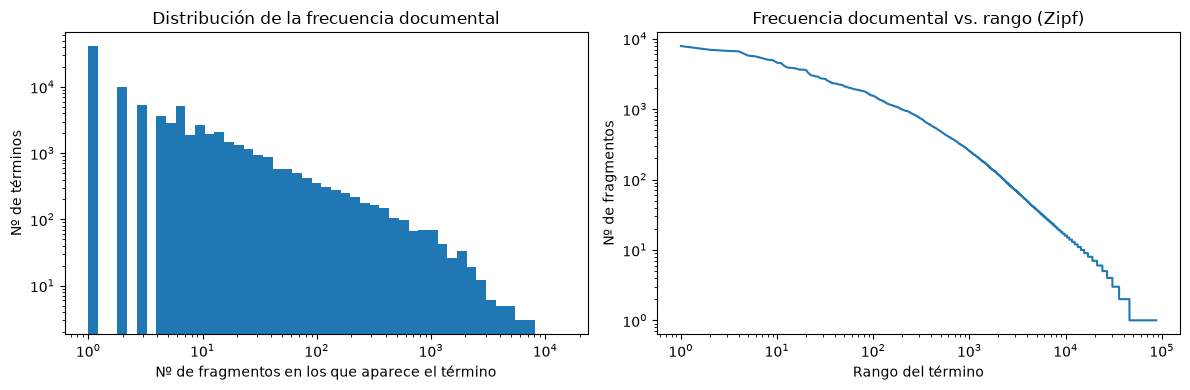

In [18]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].hist(df_tokens.ndocs, bins=np.logspace(0, np.log10(n_fragments), 50))
ax[0].set(xscale='log', yscale='log', xlabel='Nº de fragmentos en los que aparece el término', ylabel='Nº de términos',
          title='Distribución de la frecuencia documental')
ax[1].plot(np.arange(1, len(df_tokens) + 1), df_tokens.ndocs)
ax[1].set(xscale='log', yscale='log', xlabel='Rango del término', ylabel='Nº de fragmentos', title='Frecuencia documental vs. rango (Zipf)')
plt.tight_layout()

### *5.2. Elección de `no_below` y `no_above`* 🆕

El notebook usaba `no_below=4` y `no_above=0.8` para IMDB. En nuestro caso hay que tener cuidado con `no_below`: las consultas de evaluación son de tipo *known-item* (buscan un documento concreto), y el término más útil para encontrarlo suele ser un **nombre propio poco frecuente** (el nombre del satélite o de la misión). Muchos documentos de Wikipedia tienen **un solo fragmento**, así que su nombre puede aparecer en muy pocos fragmentos del corpus.

Para elegir el umbral medimos, para varios valores, qué fracción de los términos de los **títulos** de los documentos sobrevive al filtro (los títulos se preprocesan con el mismo pipeline).

In [19]:
titles = fragments_df.drop_duplicates('doc_id').set_index('doc_id').title
title_tokens = lemmatize_texts(titles.tolist())
if phrase_model is not None:
    title_tokens = [phrase_model[t] for t in title_tokens]

dfs_by_token = dict(zip(df_tokens.token, df_tokens.ndocs))
rows = []
for no_below in [1, 2, 3, 4, 5, 10]:
    for no_above in [0.5, 0.8]:
        keep = lambda t: no_below <= dfs_by_token.get(t, 0) <= no_above * n_fragments
        kept = [[t for t in toks if keep(t)] for toks in title_tokens]
        rows.append({'no_below': no_below, 'no_above': no_above,
                     'vocabulario': sum(keep(t) for t in dfs_by_token),
                     '% términos de títulos conservados': 100 * sum(map(len, kept)) / sum(map(len, title_tokens)),
                     '% títulos que pierden todos sus términos': 100 * np.mean([len(k) == 0 for k, t in zip(kept, title_tokens) if t])})
print(f'Títulos sin ningún término ya antes del filtro: {sum(len(t) == 0 for t in title_tokens)} de {len(title_tokens)}')
pd.DataFrame(rows).round(1)

Títulos sin ningún término ya antes del filtro: 14 de 2397


,no_below,no_above,vocabulario,% términos de títulos conservados,% títulos que pierden todos sus términos
0,1,0.5,87308,98.9,0.1
1,1,0.8,87309,99.7,0.1
2,2,0.5,45943,96.3,2.3
3,2,0.8,45944,97.1,2.3
4,3,0.5,35848,93.5,5.2
5,3,0.8,35849,94.3,5.2
6,4,0.5,30533,91.4,7.8
7,4,0.8,30534,92.1,7.8
8,5,0.5,26870,89.2,10.4
9,5,0.8,26871,89.9,10.3


In [20]:
print('Términos con frecuencia documental > 50 % (los que eliminaría no_above=0.5):')
print(df_tokens[df_tokens.prop > 0.5].to_string(index=False) if (df_tokens.prop > 0.5).any() else '  ninguno')
print('\nTérminos entre el 30 % y el 50 %:')
print(df_tokens[(df_tokens.prop > 0.3) & (df_tokens.prop <= 0.5)].token.tolist())

Términos con frecuencia documental > 50 % (los que eliminaría no_above=0.5):
  token  ndocs    prop
mission   7858 0.54111

Términos entre el 30 % y el 50 %:
['1', 'spacecraft', 'launch', '2', 'earth', 'orbit', 'system', 'space', '3', 'time']


**Decisión:**

* `no_below = 2`: quita los términos que aparecen en un único fragmento (casi la mitad del vocabulario, sobre todo errores de OCR y palabras unidas) y reduce el vocabulario aproximadamente a la mitad, pero solo un ~2 % de los títulos pierde todos sus términos. Con `no_below = 4`, como en el notebook, serían casi un 8 %: se pierden bastantes más nombres de misiones.
* `no_above = 0.5`: un término que aparece en más de la mitad de los fragmentos apenas sirve para distinguir unos de otros. En nuestro corpus solo elimina `mission`, así que el valor exacto (0.5 u 0.8) afecta poco.

Ambos valores son parámetros del baseline y se pueden revisar en el issue de evaluación.

In [21]:
D = Dictionary(corpus)
D.filter_extremes(no_below=CONFIG['no_below'], no_above=CONFIG['no_above'], keep_n=None)   # keep_n=None: sin límite de tamaño
print(f'Diccionario: {len(D_full):,} -> {len(D):,} términos')

Diccionario: 87,309 -> 45,943 términos


### *5.3. Aplicar el filtro a los fragmentos*

`D.doc2bow` ya ignora los términos que no están en el diccionario, así que para TF-IDF no haría falta nada más. Pero **BM25** (`bm25s`) indexa directamente las listas de tokens, así que eliminamos de cada fragmento los términos filtrados. Así los dos baselines parten exactamente del mismo texto preprocesado.

In [22]:
def filter_by_dictionary(token_lists, dictionary=None):
    vocab = (dictionary or D).token2id
    return [[t for t in toks if t in vocab] for toks in token_lists]

tokens_final = filter_by_dictionary(corpus)
fragments_df['n_tokens'] = [len(t) for t in tokens_final]

print(f'Tokens por fragmento: media {fragments_df.n_tokens.mean():.1f}, mediana {fragments_df.n_tokens.median():.0f}')
print(f'Tokens totales: {sum(map(len, corpus)):,} antes del filtro -> {fragments_df.n_tokens.sum():,} después')
print(f'Fragmentos vacíos tras el preprocesado: {(fragments_df.n_tokens == 0).sum()}')
print()
print(fragments_df.groupby('source').n_tokens.describe()[['mean', '50%', 'min', 'max']].round(1))

Tokens por fragmento: media 135.0, mediana 143
Tokens totales: 2,024,529 antes del filtro -> 1,960,425 después
Fragmentos vacíos tras el preprocesado: 0

                      mean    50%   min    max
source                                        
Apollo press kits     78.4   73.0  27.0  215.0
JPL PDFs             142.8  142.0  81.0  212.0
NTRS pilot           125.0  131.0   8.0  237.0
Wikipedia 1957–1999  151.1  150.0  87.0  228.0
Wikipedia 2000–2025  155.7  155.0  72.0  233.0


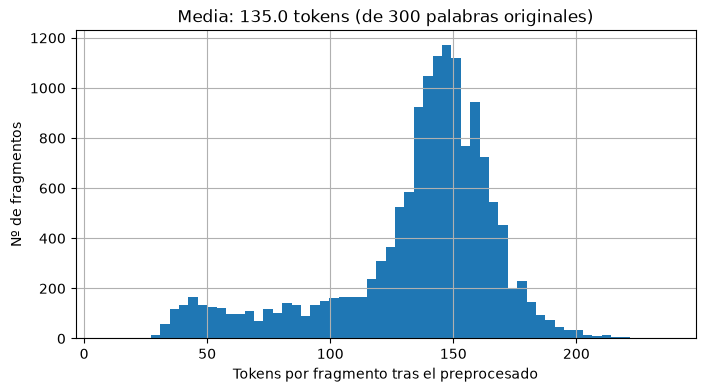

In [23]:
fragments_df.n_tokens.hist(bins=60)
plt.xlabel('Tokens por fragmento tras el preprocesado'); plt.ylabel('Nº de fragmentos')
plt.title(f'Media: {fragments_df.n_tokens.mean():.1f} tokens (de 300 palabras originales)');

In [24]:
print('Fragmentos con menos tokens (suelen ser tablas numéricas u OCR ilegible):')
fragments_df.nsmallest(5, 'n_tokens')[['chunk_id', 'title', 'source', 'n_tokens', 'text']].assign(text=lambda d: d.text.str[:150])

Fragmentos con menos tokens (suelen ser tablas numéricas u OCR ilegible):


,chunk_id,title,source,n_tokens,text
11480,doc_3236__0008,Thermal Analysis of Propulsion Components for the Europa Clipper Mission,NTRS pilot,8,7 -2.0 2.2 2.7\n\n-37.8 -38.7 -41.7 -33.9 -38.7 -36.7 -42.1 -41.0 -38.8\n\n-40.2 -40.6 -41.7 -36.6 -41.1 -39.5 -42.2...
13862,doc_3278__0030,Hubble Space Telescope: Optical telescope assembly handbook. Version 1.0,NTRS pilot,11,ure' SIzes. I not eXD.lCI Diff. Error 2 Error 1 Analytic Diameter A Simulation % % % Arcsec nm % % 0.050 0.100 0.200...
11482,doc_3236__0010,Thermal Analysis of Propulsion Components for the Europa Clipper Mission,NTRS pilot,15,"C]\n\nMLI\n\nCorrelated Model, e = 0.080\n\ne = 0.075, RMS error 2.5C TC.1 TC.2 TC.3 TC.4 TC.5 TC.6 TC.7 TC.8 TC.12 ..."
14220,doc_3300__0028,Simulation Study of a Follow-on Gravity Mission to GRACE,NTRS pilot,16,66 ± 0.61\n\n−5.04 ± 1.59\n\n−4.35 ± 1.42\n\n0.04\n\n1.18 ± 0.50\n\n0.05 ± 0.25\n\n−1.99 ± 1.25\n\n−2.76 ± 1.10\n\n0...
11481,doc_3236__0009,Thermal Analysis of Propulsion Components for the Europa Clipper Mission,NTRS pilot,21,"C] -75.0 -76.3 Average, [C] -72.9 -75.5 RMS of TC 1-8 errors, per case: Overall RMS (across all cases):\n\n-3.3 -3.0..."


## **6. Preprocesado de las consultas**

Las consultas tienen que preprocesarse **exactamente igual** que los documentos (sección 4.1 de *Text Vectorization I*): mismo `wrangle_text`, mismo pipeline de spaCy y filtros, mismo modelo de n-gramas y mismo diccionario. Por eso `preprocess_queries` no hace nada nuevo: solo encadena las mismas funciones usadas para el corpus.

In [25]:
def preprocess_texts(texts):
    # Pipeline completo para un texto nuevo (consulta): spaCy -> n-gramas -> filtro por diccionario
    toks = lemmatize_texts(texts)
    if phrase_model is not None:
        toks = [phrase_model[t] for t in toks]
    return filter_by_dictionary(toks)

preprocess_queries = preprocess_texts

**Comprobación de consistencia** 🆕: si aplicamos a los textos de algunos fragmentos el pipeline *de consultas*, tenemos que obtener exactamente los mismos tokens que guardamos para el corpus. Si alguien cambia una de las dos partes por separado, esta celda falla.

In [26]:
check_idx = fragments_df.sample(200, random_state=0).index
recomputed = preprocess_texts(fragments_df.loc[check_idx, 'text'].tolist())
mismatches = [i for i, toks in zip(check_idx, recomputed) if toks != tokens_final[i]]
assert not mismatches, f'{len(mismatches)} fragmentos no coinciden'
print('OK: el pipeline de consultas reproduce exactamente los tokens del corpus en 200 fragmentos')

OK: el pipeline de consultas reproduce exactamente los tokens del corpus en 200 fragmentos


Ejemplos de consultas como las que generará el LLM (en inglés, el idioma del corpus). Las palabras que no están en el diccionario se descartan, igual que en los documentos.

In [27]:
example_queries = [
    "Which satellite provided C-band television coverage over North America from a geostationary slot west of Hawaii?",
    "What food and sleep schedule did the crew follow during the first crewed Apollo flight?",
    "How did the team react when they discovered that the asteroid was ejecting particles?",
    "Who launched the Voyager 2 probe and when did it fly past Neptune?",
    "What happened to the mirror of the Hubble Space Telescope after launch?",
    "Spare parts delivered to the space station by shuttle flight STS-129",
]
for q, toks in zip(example_queries, preprocess_queries(example_queries)):
    print(q, '\n   ->', toks, '\n')

Which satellite provided C-band television coverage over North America from a geostationary slot west of Hawaii? 
   -> ['satellite', 'provide', 'band', 'television_coverage', 'north_america', 'geostationary', 'slot_west', 'hawaii'] 

What food and sleep schedule did the crew follow during the first crewed Apollo flight? 
   -> ['food', 'sleep', 'schedule', 'crew', 'follow', 'crew', 'apollo', 'flight'] 

How did the team react when they discovered that the asteroid was ejecting particles? 
   -> ['team', 'react', 'discover', 'asteroid', 'eject', 'particle'] 

Who launched the Voyager 2 probe and when did it fly past Neptune? 
   -> ['launch', 'voyager', '2', 'probe', 'fly', 'neptune'] 

What happened to the mirror of the Hubble Space Telescope after launch? 
   -> ['happen', 'mirror', 'hubble', 'space', 'telescope', 'launch'] 

Spare parts delivered to the space station by shuttle flight STS-129 
   -> ['spare', 'deliver', 'space_station', 'shuttle', 'flight', 'sts_129'] 



Si ya existe `queries.jsonl` en la raíz del repositorio (formato del enunciado: `{"qid": ..., "query": ..., "relevant_ids": [...], "source_chunk": ...}`), lo preprocesamos y guardamos el resultado. Si todavía no existe, esta celda no hace nada: basta con volver a ejecutarla cuando esté.

In [28]:
if QUERIES_PATH.exists():
    queries = pd.read_json(QUERIES_PATH, lines=True)
    queries['tokens'] = preprocess_queries(queries['query'].tolist())
    queries.to_json(OUT_DIR / 'consultas_preprocesadas.jsonl', orient='records', lines=True, force_ascii=False)
    print(f'{len(queries)} consultas preprocesadas. Consultas que se quedan sin ningún token:', (queries.tokens.str.len() == 0).sum())
    display(queries[['qid', 'query', 'tokens']].head(10))
else:
    print(f'No existe {QUERIES_PATH.name} todavía.')

No existe queries.jsonl todavía.


## **7. Guardar los resultados**

In [29]:
with (OUT_DIR / 'fragmentos_preprocesados.jsonl').open('w', encoding='utf-8') as f:
    for chunk_id, doc_id, toks in zip(fragments_df.chunk_id, fragments_df.doc_id, tokens_final):
        f.write(json.dumps({'chunk_id': chunk_id, 'doc_id': doc_id, 'tokens': toks}, ensure_ascii=False) + '\n')

D.save(str(OUT_DIR / 'diccionario.dict'))
if phrase_model is not None:
    phrase_model.save(str(OUT_DIR / 'ngramas.phrases'))

stats = {'n_fragments': int(n_fragments), 'n_documents': int(fragments_df.doc_id.nunique()),
         'vocab_before_filter': len(D_full), 'vocab_after_filter': len(D),
         'n_ngrams': len(phrase_model.phrasegrams) if phrase_model else 0,
         'mean_tokens_per_fragment': round(float(fragments_df.n_tokens.mean()), 1),
         'spacy_version': spacy.__version__}
with (OUT_DIR / 'config_preprocesado.json').open('w', encoding='utf-8') as f:
    json.dump({'config': CONFIG, 'stats': stats}, f, indent=2, ensure_ascii=False)

for p in sorted(OUT_DIR.iterdir()):
    print(f'{p.name:35s} {p.stat().st_size / 1e6:6.1f} MB')
print(json.dumps(stats, indent=2))

config_preprocesado.json               0.0 MB
diccionario.dict                       1.1 MB
fragmentos_preprocesados.jsonl        22.3 MB
lemas_spacy.jsonl                     23.6 MB
ngramas.phrases                        0.3 MB
{
  "n_fragments": 14522,
  "n_documents": 2397,
  "vocab_before_filter": 87309,
  "vocab_after_filter": 45943,
  "n_ngrams": 13679,
  "mean_tokens_per_fragment": 135.0,
  "spacy_version": "3.8.18"
}


### *Cómo usarlo en el issue de los baselines (TF-IDF y BM25)*

```python
import json
import pandas as pd
from gensim.corpora import Dictionary
from gensim.models.phrases import FrozenPhrases

frags = pd.read_json('preprocesado/fragmentos_preprocesados.jsonl', lines=True)
corpus = frags.tokens.tolist()                          # para bm25s.BM25().index(corpus)
D = Dictionary.load('preprocesado/diccionario.dict')
corpus_bow = [D.doc2bow(doc) for doc in corpus]         # para TfidfModel(corpus_bow)
```

Para las consultas hay que usar la función `preprocess_queries` de este notebook (o moverla a un módulo `.py` compartido, cargando `ngramas.phrases` con `FrozenPhrases.load` y el diccionario).

---
## **Resumen de decisiones (para `MILESTONE_1.md`)**

| Paso | Decisión | Origen |
|---|---|---|
| Unidad de indexación | Fragmentos de 300 palabras (`misiones_300.jsonl`); las estadísticas se calculan sobre fragmentos | Enunciado del Hito 1 |
| Limpieza del texto | Quitar URLs; re-segmentar con `wordninja` el OCR con letras separadas; unir palabras cortadas a final de línea; separar identificadores con guion (`STS-129` → `STS 129`). Sin BeautifulSoup ni `contractions` | TV-I §1.2.1, adaptado 🆕 |
| Tokenización y lematización | spaCy `en_core_web_sm` (sin `parser` ni `ner`), `nlp.pipe` en lotes, lemas en minúsculas | TV-I §1.2.3 y §1.3 |
| Filtrado POS | `NOUN`, `VERB`, `ADJ`, `PROPN` | TV-I §1.3 |
| Stopwords | spaCy + específicas del dominio (`et`, `al`, `fig`, `figure`, `table`...) | TV-I §1.2.4 / §1.3 |
| Otros filtros | Longitud mínima 2; se conservan números y códigos alfanuméricos de ≤ 4 caracteres (`11`, `2b`, `1969`) | 🆕 |
| N-gramas | Gensim `Phrases(min_count=5, threshold=20)`, congelado | TV-I §2.2 |
| Frecuencia documental | `filter_extremes(no_below=2, no_above=0.5)` sobre fragmentos | TV-I §2.3 / Ej. 8, umbrales 🆕 |
| Consultas | Mismo pipeline (`preprocess_queries`), comprobado automáticamente | TV-I §4.1 |